In [1]:

from enum import Enum
from pathlib import Path
from datetime import datetime, timezone
import time
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# Dossier de sortie
DATA_DIR = Path("data/kialo")
RAW_DIR = DATA_DIR / "raw"
DEBATES_DIR = RAW_DIR / "debates"
PROCESSED_DIR = DATA_DIR / "processed"
FIGURES_DIR = DATA_DIR / "figures"

for folder in [DEBATES_DIR, PROCESSED_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Paramètres de collecte
N_DISCUSSIONS = 250
REQUEST_DELAY = 1.0
RANDOM_SEED = 42

sns.set_theme(style="whitegrid")


In [2]:
# function from https://github.com/4mbroise/ADC/blob/main/tool/kialo.ipynb 

class KialoSort(Enum):
    RANK_ACTIVITY = "rank_and_latest_activity"
    VIEW = "view_count"
    LAST_ACTIVITY = "latest_activity"


class KialoFilter(Enum):
    PROMOTED = "promoted"
    PARTICIPATE = "participate"
    LAST_ACTIVITY = "latest_activity"
    TAG = "tag"
    TAG_ALL = "tag_all"


class KialoTool:
    BASE_URL = "https://www.kialo.com/api/v1"

    def __init__(self, delay=1.0):
        self.session = requests.Session()
        self.session.headers.update({
            "User-Agent": "Academic research project"
        })
        self.delay = delay

    def get_tags(self):
        response = self.session.get(
            f"{self.BASE_URL}/discussiontags",
            timeout=30
        )
        response.raise_for_status()
        time.sleep(self.delay)
        return [
            item["tagName"]
            for item in response.json().get("tags", [])
        ]

    def get_discussions(
        self,
        filter=KialoFilter.TAG,
        sort=KialoSort.RANK_ACTIVITY,
        limit=250,
        skip=0
    ):
        response = self.session.get(
            f"{self.BASE_URL}/discussions",
            params={
                "filter": filter.value,
                "sort": sort.value,
                "limit": limit,
                "skip": skip
            },
            timeout=30
        )
        response.raise_for_status()
        time.sleep(self.delay)
        payload = response.json()
        return payload.get("discussions", [])


k = KialoTool(delay=REQUEST_DELAY)


In [3]:

discussions = k.get_discussions(
    filter=KialoFilter.TAG,
    sort=KialoSort.RANK_ACTIVITY,
    limit=N_DISCUSSIONS,
    skip=0
)

print("Discussions récupérées :", len(discussions))

if not discussions:
    raise RuntimeError(
        "Aucune discussion reçue. Vérifie la réponse de l'API "
        "et les conditions d'accès de Kialo."
    )

# Sauvegarder la réponse brute pour rendre l'expérience reproductible
with open(RAW_DIR / "discussions_raw.json", "w", encoding="utf-8") as f:
    import json
    json.dump(discussions, f, ensure_ascii=False, indent=2)


Discussions récupérées : 250


In [4]:

import re
import unicodedata

def make_url_id(title, discussion_id):
  """Construit le slug nettoyé pour l'URL d'export Kialo."""
  title = unicodedata.normalize("NFKC", str(title)).lower()
  # Remplacer les slashs et supprimer les apostrophes/points d'interrogation
  title = (
      title.replace("/", "-")
      .replace("?", "")
      .replace("'", "")
      .replace('"', "")
  )
  # Remplacer les espaces et caractères non alphanumériques
  title = re.sub(r"[^\w\s-]", "", title)
  title = re.sub(r"[\s_]+", "-", title.strip())
  title = re.sub(r"-+", "-", title)  # Éviter les doubles tirets '--'
  return f"{title}-{discussion_id}"


def discussions_to_dataframe(discussions):
    rows = []

    for rank, item in enumerate(discussions, start=1):
        discussion_id = item.get("id")
        title = item.get("title", "")
        tags = item.get("tags", [])

        rows.append({
            "rank_in_api": rank,
            "discussion_id": discussion_id,
            "title": title,
            "kialo_url_id": make_url_id(title, discussion_id),
            "url": (
                f"https://www.kialo.com/"
                f"{make_url_id(title, discussion_id)}"
            ),
            "tags": tags,
            "n_tags": len(tags) if isinstance(tags, list) else np.nan,
            "collected_at_utc": datetime.now(
                timezone.utc
            ).isoformat()
        })

    return pd.DataFrame(rows)


discussions_df = discussions_to_dataframe(discussions)

# Nettoyage minimal
discussions_df = discussions_df.drop_duplicates(
    subset="discussion_id"
).reset_index(drop=True)

discussions_df.to_csv(
    PROCESSED_DIR / "discussions_metadata.csv",
    index=False,
    encoding="utf-8"
)

discussions_df.head()


,rank_in_api,discussion_id,title,kialo_url_id,url,tags,n_tags,collected_at_utc
0,1,29355,Are Purity Pledges Harmful?,are-purity-pledges-harmful-29355,https://www.kialo.com/are-purity-pledges-harmf...,"[Purity, Sex, Virginity, Feminism, Women]",5,2026-10-18T14:04:26.355539+00:00
1,2,10143,Should American Football Be Banned?,should-american-football-be-banned-10143,https://www.kialo.com/should-american-football...,"[Sports, USA, Football, American_Football, Ent...",5,2026-10-18T14:04:26.355719+00:00
2,3,30339,Should there be One World State?,should-there-be-one-world-state-30339,https://www.kialo.com/should-there-be-one-worl...,"[States, Nations, Culture, Economics, Politics]",5,2026-10-18T14:04:26.355836+00:00
3,4,31027,Do fair trade products cause more good than harm?,do-fair-trade-products-cause-more-good-than-ha...,https://www.kialo.com/do-fair-trade-products-c...,"[Trade, Development, International, Ethics]",4,2026-10-18T14:04:26.355964+00:00
4,5,64072,Should failing banks receive bailouts from the...,should-failing-banks-receive-bailouts-from-the...,https://www.kialo.com/should-failing-banks-rec...,"[Economy, Finance, States, Government, Banks, ...",6,2026-10-18T14:04:26.356062+00:00


In [5]:
# 1. Suppression des fichiers texte contenant du HTML
deleted_count = 0
for file_path in DEBATES_DIR.glob("*.txt"):
    try:
        content = file_path.read_text(encoding="utf-8", errors="ignore")
        if "<!DOCTYPE html>" in content or "login" in content[:500]:
            file_path.unlink()
            deleted_count += 1
    except Exception as e:
        print(f"Erreur lors de la lecture de {file_path.name} : {e}")

print(f"{deleted_count} fichiers HTML corrompus ont été supprimés.")


0 fichiers HTML corrompus ont été supprimés.


In [6]:
import time
from pathlib import Path
import requests
from tqdm.auto import tqdm

# Configuration des cookies extraits de DevTools
COOKIES = {
    "kialo-login-session-2": "2|8:20261001|10:1792153319|21:kialo-login-session-2|52:ZTZiM2I1M2MtODFlZC00ZWVhLWI3NTctOWJlZTc1ZmU0NDk0LDA=|4ad1ae74bab7d85bac1485920d5683b68b61f18d23a3c3cc86e31e71be7fa73f",  
    "_xsrf": "2|72d3f0dd|a1765feda73ecf4360c3ead786df7d93|...",
    "url_user_language": "fr"
}

def download_discussions_authenticated(url_ids, download_dir, cookies_dict, delay=1.0):
    download_dir = Path(download_dir).resolve()
    download_dir.mkdir(parents=True, exist_ok=True)

    session = requests.Session()
    session.headers.update({
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
        "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8"
    })
    
    # Injection des cookies de session dans la requête
    for name, value in cookies_dict.items():
        session.cookies.set(name, value, domain="www.kialo.com")

    success_count = 0

    for url_id in tqdm(url_ids, desc="Export des débats"):
        file_path = download_dir / f"{url_id}.txt"

        if file_path.exists():
            continue

        export_url = f"https://www.kialo.com/export/{url_id}.txt"

        try:
            response = session.get(export_url, timeout=30)
            
            # Vérification : s'assurer que la réponse contient du texte brut et non le HTML de login
            if response.status_code == 200 and not response.text.strip().startswith("<!DOCTYPE html>"):
                file_path.write_text(response.text, encoding="utf-8")
                success_count += 1
            else:
                print(f"Échec d'authentification pour : {url_id} (Status: {response.status_code})")
        except Exception as e:
            print(f"Erreur pour {url_id} : {e}")

        time.sleep(delay)

    print(f"\nTéléchargement terminé : {success_count} fichiers valides enregistrés dans {download_dir}")

# Lancement du téléchargement
download_discussions_authenticated(
    discussions_df["kialo_url_id"].tolist(), 
    DEBATES_DIR, 
    COOKIES, 
    delay=REQUEST_DELAY
)

Export des débats:   0%|          | 0/250 [00:00<?, ?it/s]


Téléchargement terminé : 1 fichiers valides enregistrés dans /mnt/c/Users/mel77/OneDrive/Documents/COURS/M2/DYCO/dyco/src/data/kialo/raw/debates


In [7]:

txt_files = sorted(DEBATES_DIR.glob("*.txt"))

print("Nombre de fichiers texte :", len(txt_files))

preview_rows = []

for file_path in txt_files:
    text = file_path.read_text(encoding="utf-8", errors="replace")

    preview_rows.append({
        "filename": file_path.name,
        "n_chars": len(text),
        "n_lines": len(text.splitlines()),
        "empty": not text.strip()
    })

files_df = pd.DataFrame(preview_rows)

if not files_df.empty:
    display(files_df.head(10))
    print("\nRésumé des fichiers :")
    display(files_df[["n_chars", "n_lines"]].describe())
else:
    print(
        "Aucun fichier trouvé. Vérifie le dossier de téléchargement "
        "et exécute l'export si tu disposes d'un accès autorisé."
    )


Nombre de fichiers texte : 251


,filename,n_chars,n_lines,empty
0,according-to-the-bible-salvation-is-by-faith-a...,87364,1314,False
1,affirmative-action-useful-once-outdated-today-...,179051,2571,False
2,all-humans-should-be-vegan-2762.txt,609990,5246,False
3,are-electric-guitars-better-than-acoustic-guit...,29717,512,False
4,are-ghosts-real-23956.txt,61219,1009,False
5,are-humans-fundamentally-different-from-other-...,40850,664,False
6,are-men-the-biggest-problem-mankind-faces-1362...,30584,391,False
7,are-purity-pledges-harmful-29355.txt,93724,1448,False
8,are-trans-women-real-women-57536.txt,133339,1424,False
9,are-video-games-art-27596.txt,26699,519,False



Résumé des fichiers :


,n_chars,n_lines
count,2.510000e+02,251.000000
mean,1.356371e+05,1625.438247
std,1.850182e+05,1885.959904
min,7.820000e+02,32.000000
25%,2.899150e+04,469.000000
50%,7.727700e+04,1127.000000
75%,1.760805e+05,2163.500000
max,1.719829e+06,13793.000000


In [8]:

if txt_files:
    sample_text = txt_files[0].read_text(
        encoding="utf-8",
        errors="replace"
    )
    print(sample_text[:5000])


Discussion Name:
According to the Bible, salvation is by faith alone (sola fide)

1. Thesis:
According to the Bible, salvation is by faith alone (sola fide).

  1.1. Con:
  Baptism is also required for salvation.

    1.1.1. Pro:
    Mark 16:16 [1] says that "Whoever believes and is baptized will be saved."

      1.1.1.1. Con:
      The portion of Mark where this verse appears is missing from "the earliest manuscripts and some other ancient witnesses [2]."

      1.1.1.2. Con:
      This passage may imply that all who believe and are baptized are saved. However, this does not mean that those who believe but are not baptized are not saved.

    1.1.2. Pro:
    Galatians 3:27 [3] says that "all of you who were baptized into Christ have clothed yourselves with Christ."

      1.1.2.1. Con:
      This passage is not necessarily referring to water baptism.

        1.1.2.1.1. Pro:
        1 Corinthians 12:13 [4] discusses a nonliteral, spiritual baptism into Christ. Therefore, baptism into

Nombre de discussions : 250
Nombre d'identifiants distincts : 250
Titres manquants : 0


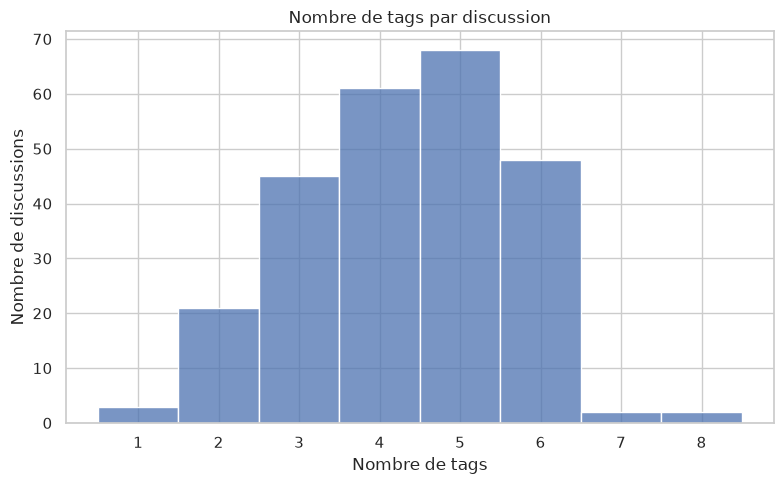

In [9]:

print("Nombre de discussions :", len(discussions_df))
print("Nombre d'identifiants distincts :",
      discussions_df["discussion_id"].nunique())
print("Titres manquants :", discussions_df["title"].isna().sum())

discussions_df["n_tags"] = pd.to_numeric(
    discussions_df["n_tags"], errors="coerce"
)

plt.figure(figsize=(8, 5))
sns.histplot(
    discussions_df["n_tags"].dropna(),
    discrete=True
)
plt.title("Nombre de tags par discussion")
plt.xlabel("Nombre de tags")
plt.ylabel("Nombre de discussions")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tags_per_discussion.png", dpi=150)
plt.show()


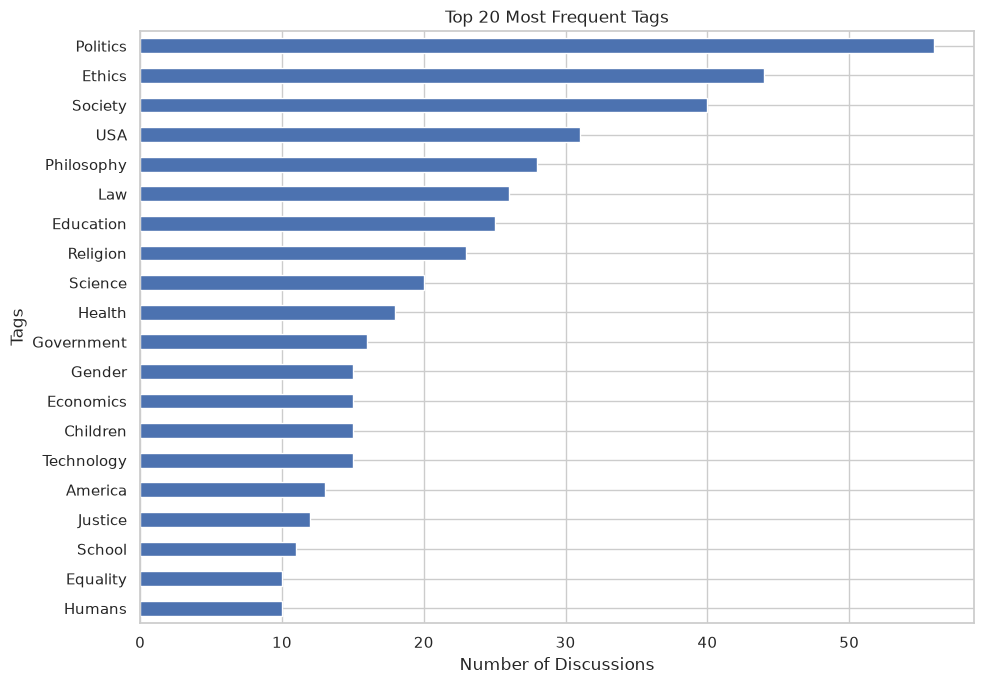

,number_of_discussions
tag,
Politics,56
Ethics,44
Society,40
USA,31
Philosophy,28
Law,26
Education,25
Religion,23
Science,20


In [10]:

tag_rows = []

for _, row in discussions_df.iterrows():
    tags = row["tags"]
    if isinstance(tags, list):
        for tag in tags:
            tag_rows.append({
                "discussion_id": row["discussion_id"],
                "tag": tag
            })

tags_df = pd.DataFrame(tag_rows)

if not tags_df.empty:
    top_tags = (
        tags_df.groupby("tag")["discussion_id"]
        .nunique()
        .sort_values(ascending=False)
        .head(20)
        .sort_values()
    )

    plt.figure(figsize=(10, 7))
    top_tags.plot(kind="barh")
    plt.title("Top 20 Most Frequent Tags")
    plt.xlabel("Number of Discussions")
    plt.ylabel("Tags")
    
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "top_20_tags.png", dpi=150)
    plt.show()

    display(top_tags.sort_values(ascending=False).to_frame(
        "number_of_discussions"
    ))
else:
    print("No usable tags found in the received metadata.")


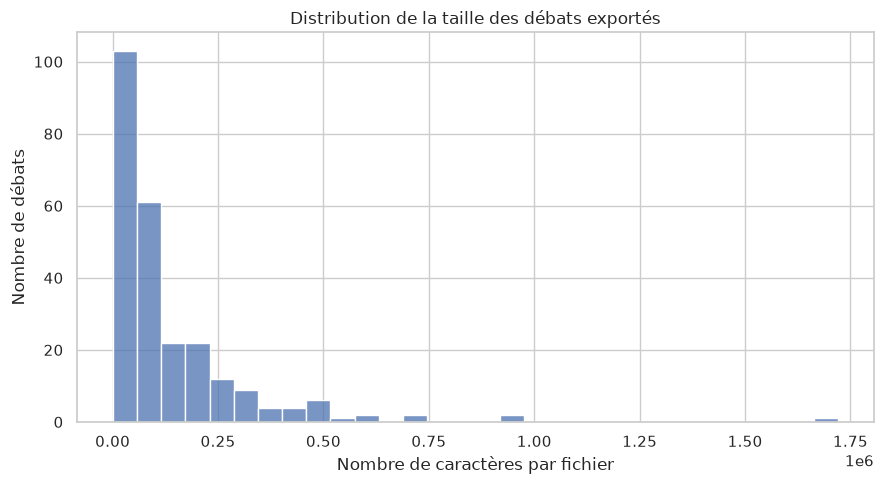

Taille médiane (caractères) : 77277.0
Taille moyenne (caractères) : 135637.11


In [11]:

if not files_df.empty:
    plt.figure(figsize=(9, 5))
    sns.histplot(files_df["n_chars"], bins=30)
    plt.title("Distribution de la taille des débats exportés")
    plt.xlabel("Nombre de caractères par fichier")
    plt.ylabel("Nombre de débats")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "debate_file_sizes.png", dpi=150)
    plt.show()

    print("Taille médiane (caractères) :",
          files_df["n_chars"].median())
    print("Taille moyenne (caractères) :",
          round(files_df["n_chars"].mean(), 2))
